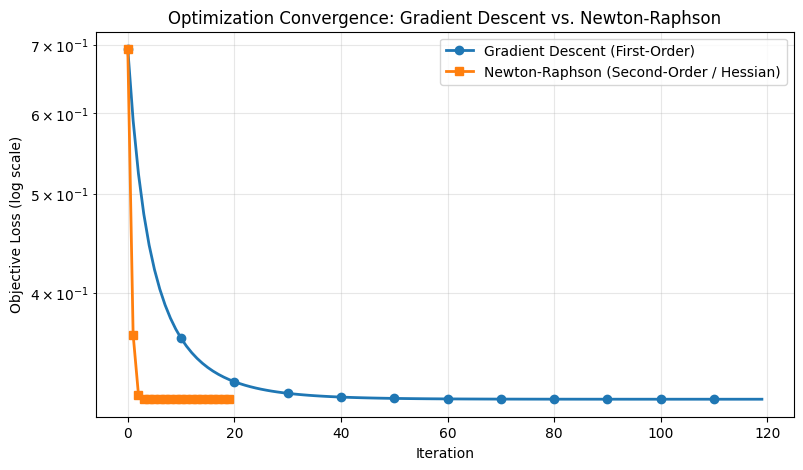

GD final params:         [-0.3844  1.2258 -1.4005]
Newton-Raphson params:   [-0.3871  1.2279 -1.4032]
True [b, w1, w2]:        [-0.4  1.8 -2.2]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Synthetic binary classification dataset banayein
rng = np.random.default_rng(42)
n_samples = 400
X_raw = rng.normal(0, 1.5, size=(n_samples, 2))
true_w = np.array([1.8, -2.2])
true_b = -0.4

logits = X_raw @ true_w + true_b + rng.normal(0, 0.35, size=n_samples)
y = (logits > 0).astype(float)

# Add bias column -> X shape: (n_samples, 3)
X = np.column_stack([np.ones(n_samples), X_raw])
lam = 0.05  # L2 regularization parameter

def sigmoid(z):
    z = np.clip(z, -30, 30)
    return 1.0 / (1.0 + np.exp(-z))

def loss_and_grad(theta):
    # Negative log-likelihood (cross-entropy) + L2 penalty (bias not penalized)
    p = sigmoid(X @ theta)
    eps = 1e-12
    nll = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
    reg_mask = np.array([0.0, 1.0, 1.0])
    loss = nll + 0.5 * lam * np.sum((reg_mask * theta) ** 2)
    grad = (X.T @ (p - y)) / n_samples + lam * (reg_mask * theta)
    return loss, grad

def hessian(theta):
    p = sigmoid(X @ theta)
    w_diag = p * (1.0 - p)
    Xw = X * w_diag[:, None]
    reg_mat = np.diag([0.0, lam, lam])
    return (X.T @ Xw) / n_samples + reg_mat

# 2. Gradient Descent (from scratch)
theta_gd = np.zeros(X.shape[1])
lr = 0.4
gd_losses = []
for _ in range(120):
    l, g = loss_and_grad(theta_gd)
    gd_losses.append(l)
    theta_gd -= lr * g

# 3. Newton-Raphson (from scratch)
theta_nr = np.zeros(X.shape[1])
nr_losses = []
for _ in range(20):
    l, g = loss_and_grad(theta_nr)
    nr_losses.append(l)
    H = hessian(theta_nr)
    step = np.linalg.solve(H, g)
    theta_nr -= step

# 4. Plot convergence comparison
plt.figure(figsize=(9, 5))
plt.semilogy(gd_losses, "o-", markevery=10, label="Gradient Descent (First-Order)", linewidth=2)
plt.semilogy(nr_losses, "s-", label="Newton-Raphson (Second-Order / Hessian)", linewidth=2)
plt.title("Optimization Convergence: Gradient Descent vs. Newton-Raphson")
plt.xlabel("Iteration")
plt.ylabel("Objective Loss (log scale)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

print("GD final params:        ", np.round(theta_gd, 4))
print("Newton-Raphson params:  ", np.round(theta_nr, 4))
print("True [b, w1, w2]:       ", np.round(np.concatenate([[true_b], true_w]), 4))

Newton-Raphson Training Accuracy: 97.00%
Adam (from scratch) Accuracy:     97.00%
Adam params [b, w1, w2]:         [-0.3874  1.1845 -1.4585]


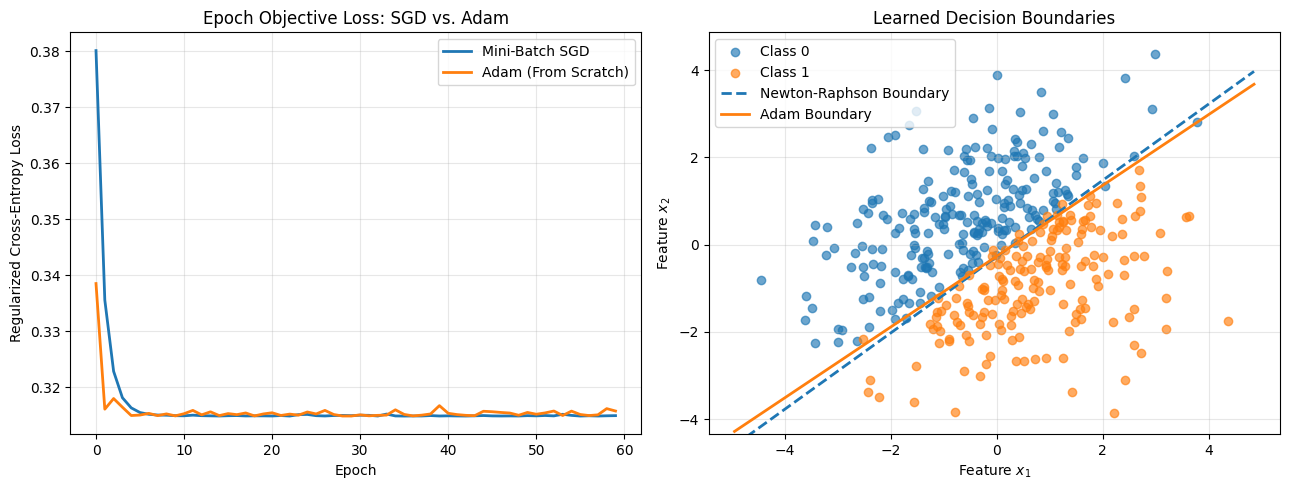

In [3]:
# Cell 2: Mini-Batch SGD vs. Adam (From Scratch) + Decision Boundary & Accuracy

def train_sgd_and_adam(X_data, y_data, reg_lambda=0.05, batch_size=32, epochs=60):
    rng = np.random.default_rng(101)
    n, d = X_data.shape
    reg_mask = np.array([0.0] + [1.0] * (d - 1))

    # --- Mini-Batch SGD ---
    w_sgd = np.zeros(d)
    lr_sgd = 0.25
    sgd_loss_hist = []

    # --- Adam Optimizer (from scratch) ---
    w_adam = np.zeros(d)
    m = np.zeros(d)
    v = np.zeros(d)
    beta1, beta2, eps, lr_adam = 0.9, 0.999, 1e-8, 0.08
    adam_loss_hist = []
    t_step = 0

    def full_loss(theta):
        p = sigmoid(X_data @ theta)
        nll = -np.mean(y_data * np.log(p + 1e-12) + (1 - y_data) * np.log(1 - p + 1e-12))
        return nll + 0.5 * reg_lambda * np.sum((reg_mask * theta) ** 2)

    for _ in range(epochs):
        perm = rng.permutation(n)
        X_shuf, y_shuf = X_data[perm], y_data[perm]

        for start in range(0, n, batch_size):
            xb = X_shuf[start:start + batch_size]
            yb = y_shuf[start:start + batch_size]
            b_len = len(yb)

            # SGD update
            pb_sgd = sigmoid(xb @ w_sgd)
            grad_sgd = (xb.T @ (pb_sgd - yb)) / b_len + reg_lambda * (reg_mask * w_sgd)
            w_sgd -= lr_sgd * grad_sgd

            # Adam update
            t_step += 1
            pb_adam = sigmoid(xb @ w_adam)
            grad_adam = (xb.T @ (pb_adam - yb)) / b_len + reg_lambda * (reg_mask * w_adam)
            m = beta1 * m + (1 - beta1) * grad_adam
            v = beta2 * v + (1 - beta2) * (grad_adam ** 2)
            m_hat = m / (1 - beta1 ** t_step)
            v_hat = v / (1 - beta2 ** t_step)
            w_adam -= lr_adam * m_hat / (np.sqrt(v_hat) + eps)

        sgd_loss_hist.append(full_loss(w_sgd))
        adam_loss_hist.append(full_loss(w_adam))

    return w_sgd, sgd_loss_hist, w_adam, adam_loss_hist

w_sgd, sgd_hist, w_adam, adam_hist = train_sgd_and_adam(X, y, reg_lambda=lam)

# Accuracy calculation using Newton-Raphson model
preds_nr = (sigmoid(X @ theta_nr) >= 0.5).astype(float)
acc_nr = np.mean(preds_nr == y) * 100

preds_adam = (sigmoid(X @ w_adam) >= 0.5).astype(float)
acc_adam = np.mean(preds_adam == y) * 100

print(f"Newton-Raphson Training Accuracy: {acc_nr:.2f}%")
print(f"Adam (from scratch) Accuracy:     {acc_adam:.2f}%")
print("Adam params [b, w1, w2]:        ", np.round(w_adam, 4))

# Plot Epoch Loss + Decision Boundary
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(sgd_hist, label="Mini-Batch SGD", linewidth=2)
ax1.plot(adam_hist, label="Adam (From Scratch)", linewidth=2)
ax1.set_title("Epoch Objective Loss: SGD vs. Adam")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Regularized Cross-Entropy Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Decision boundary for Newton-Raphson & Adam
x1_grid = np.linspace(X_raw[:, 0].min() - 0.5, X_raw[:, 0].max() + 0.5, 200)
ax2.scatter(X_raw[y == 0, 0], X_raw[y == 0, 1], alpha=0.65, label="Class 0")
ax2.scatter(X_raw[y == 1, 0], X_raw[y == 1, 1], alpha=0.65, label="Class 1")

# b + w1*x1 + w2*x2 = 0  =>  x2 = -(b + w1*x1)/w2
x2_nr = -(theta_nr[0] + theta_nr[1] * x1_grid) / theta_nr[2]
x2_adam = -(w_adam[0] + w_adam[1] * x1_grid) / w_adam[2]

ax2.plot(x1_grid, x2_nr, "--", linewidth=2, label="Newton-Raphson Boundary")
ax2.plot(x1_grid, x2_adam, "-", linewidth=2, label="Adam Boundary")
ax2.set_ylim(X_raw[:, 1].min() - 0.5, X_raw[:, 1].max() + 0.5)
ax2.set_title("Learned Decision Boundaries")
ax2.set_xlabel("Feature $x_1$")
ax2.set_ylabel("Feature $x_2$")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()